In [56]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import math
import matplotlib.pyplot as plt
from tqdm import tqdm

In [4]:
animals = ['aardvark', 'albatross', 'alligator', 'alpaca', 'anole', 'ant', 'anteater', 'antelope', 'ape', 'armadillo',
           'baboon', 'badger', 'barracuda', 'bat', 'bear', 'bee', 'bison', 'boar', 'bobcat', 'butterfly']
vocab = {w: i for i,w in enumerate(animals)}
a_names = [a for a in animals if a[0] == 'a']
b_names = [b for b in animals if b[0] == 'b']


def make_animal_data():
    np.random.seed(42)
    animal_data = pd.DataFrame(zip(np.random.choice(a_names, size=300),
                                   np.random.choice(a_names, size=300)),
                              columns=['w1', 'w2'])
    animal_data = pd.concat((animal_data,
                           pd.DataFrame(zip(np.random.choice(b_names, size=300),
                                            np.random.choice(b_names, size=300)),
                              columns=['w1', 'w2'])))
    animal_data = animal_data.sample(frac=1, random_state=42)
    # remove where w1==w2
    animal_data = animal_data[animal_data.w1 != animal_data.w2]#.drop_duplicates()
    return animal_data

data = make_animal_data()
data

,w1,w2
110,aardvark,ant
119,bat,bear
265,bee,butterfly
77,ape,albatross
181,anole,armadillo
...,...,...
121,armadillo,aardvark
20,anole,ant
71,anole,ant
270,alpaca,albatross


In [69]:
class WordpairModel(nn.Module):
    def __init__(self, vocab_size, embedding_size, verbose = False): # automatic
        super(WordpairModel, self).__init__() # book keeping of the instance
        # layers
        self.verbose = verbose

        # input -> hidden
        #nn.Linear = xA^T + b # holding the layer
        self.embedding = nn.Linear(vocab_size, embedding_size) # weight metrix has vocab_size rows and embedding_size columns
        
        # hidden -> output (logits; dont softmax here (why?: ))
        self.hidden = nn.Linear(embedding_size, vocab_size, bias =False)
        self.softmax = nn.Softmax(dim=1)


    def forward(self, input):
        if self.verbose:
            print('input\n', input)

        embedding = self.embedding(input)
        if self.verbose:
            print('embedding\n', embedding)
        
        logits = self.hidden(embedding)
        if self.verbose:
            print('logits\n', logits)

        if self.verbose:
            print('softmax\n', self.softmax(logits))

        return logits


In [70]:
def vectorize_one(word, vocabulary):
    """ one-hot encoding"""
    tensor = torch.zeros(1, len(vocabulary))
    tensor[0][vocabulary[word]] = 1.0
    return tensor

def vectorize_batch(rows, vocabulary):
    """
    encode all examples in given list of rows in DataFrame.
    """
    return (torch.cat([vectorize_one(w, vocabulary) for w in rows.w1]),
            torch.cat([vectorize_one(w, vocabulary) for w in rows.w2]))

vectorize_one('anole', vocab)

x = vectorize_batch(data.iloc[:3], vocab)

### computing forward pass for the first example

In [71]:
torch.manual_seed(42)
model = WordpairModel(len(vocab), embedding_size=2, verbose=True)

output = model(vectorize_batch(data.iloc[:1], vocab)[0])

input
 tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0.]])
embedding
 tensor([[ 0.2310, -0.1637]], grad_fn=<AddmmBackward0>)
logits
 tensor([[-0.0346,  0.1450,  0.0736,  0.1535, -0.1170, -0.2203, -0.0009,  0.0537,
          0.2101,  0.0893,  0.0902,  0.0742,  0.2041, -0.0284,  0.1084,  0.2527,
         -0.0715, -0.1568, -0.0377, -0.0055]], grad_fn=<MmBackward0>)
softmax
 tensor([[0.0461, 0.0552, 0.0514, 0.0556, 0.0425, 0.0383, 0.0477, 0.0504, 0.0589,
         0.0522, 0.0522, 0.0514, 0.0585, 0.0464, 0.0532, 0.0614, 0.0444, 0.0408,
         0.0460, 0.0475]], grad_fn=<SoftmaxBackward0>)


In [72]:
vectorize_batch(data.iloc[:1], vocab)[0].shape

torch.Size([1, 20])

#### understanding what forward did

In [73]:
# so a one tensor from the dataset
i = vectorize_batch(data.iloc[:1], vocab)[0]
print('i:', i)

# i = 1 X 20 and the embedding layer is 20 X 2
e = i.mul(model.embedding.weight).sum(dim =1)
print('e', e)

# e is now 1 X 2
h = e.mul(model.hidden.weight).sum(dim = 1)
print('h', h)

#now back to 1 X 20
o = h.exp() / h.exp().sum()
print('o', o)

i: tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0.]])
e tensor([ 0.1710, -0.1030], grad_fn=<SumBackward1>)
h tensor([-0.0142,  0.1017,  0.0567,  0.1058, -0.0915, -0.1525,  0.0046,  0.0395,
         0.1464,  0.0573,  0.0624,  0.0522,  0.1434, -0.0286,  0.0845,  0.1764,
        -0.0629, -0.1108, -0.0172, -0.0128], grad_fn=<SumBackward1>)
o tensor([0.0478, 0.0537, 0.0513, 0.0539, 0.0442, 0.0416, 0.0487, 0.0504, 0.0561,
        0.0513, 0.0516, 0.0511, 0.0560, 0.0471, 0.0528, 0.0578, 0.0455, 0.0434,
        0.0477, 0.0479], grad_fn=<DivBackward0>)


100%|██████████| 80/80 [00:00<00:00, 132.56it/s]


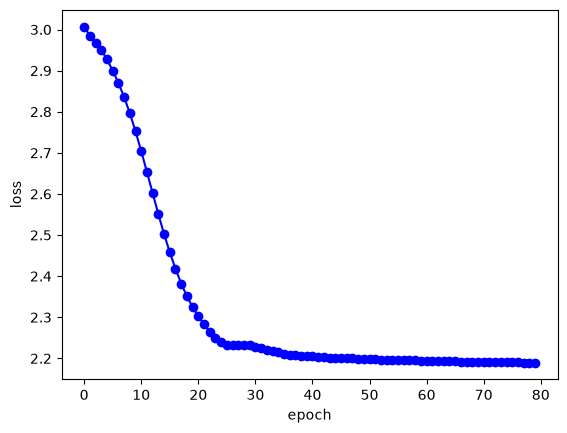

In [74]:
def train_word_pair(data, vocab):
    torch.random.manual_seed(42)
    learning_rate = 0.1
    model = WordpairModel(len(vocab), embedding_size=2)

    # using binary cross entropy
    criterion = nn.CrossEntropyLoss()

    #fancier version of gradient descent
    optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate)
    model.verbose = False

    loss_val = []
    num_epochs = 80

    #main training loop
    for epoch in tqdm(range(num_epochs), total=num_epochs): # progress bar
        optimizer.zero_grad() # resetting all the gradient information
        inputs, labels = vectorize_batch(data, vocab)
        outputs = model(inputs)
        labels = labels.argmax(axis=1)
        loss = criterion(outputs, labels)
        loss.backward() # computing all the gradients
        optimizer.step() # update parameters
        loss_val.append(loss.item())


    plt.figure()
    plt.plot(loss_val, 'bo-')
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.show()

    return model


word_pair_model = train_word_pair(data, vocab)

In [79]:
# now we can get word embeddings

def word2embedding(word, model, vocabulary):
    return model.embedding(vectorize_one(word, vocabulary)).detach().cpu().numpy()[0]

word2embedding('ant', word_pair_model, vocab)

array([-0.42205557, -1.4194372 ], dtype=float32)

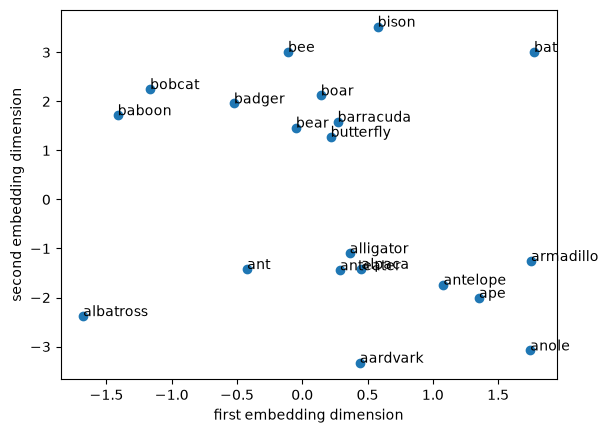

In [80]:
def plot_embeddings(animal_embeddings, animals):
    plt.figure()
    plt.scatter([e[0] for e in animal_embeddings],
                [e[1] for e in animal_embeddings])
    for animal, embed in zip(animals, animal_embeddings):
        plt.annotate(animal, (embed[0], embed[1]))
    plt.xlabel('first embedding dimension')
    plt.ylabel('second embedding dimension')
    plt.show()

animal_embeddings = [word2embedding(animal, word_pair_model, vocab) for animal in animals]
plot_embeddings(animal_embeddings, animals)

In [82]:
# add negative examples
def add_negatives(data):
    np.random.seed(42)
    data2 = data.copy()
    data2 = pd.concat((data2,
                      pd.DataFrame(zip(np.random.choice(a_names, size=400), np.random.choice(b_names, size=400)), columns=['w1', 'w2'])))
    data2 = pd.concat((data2,
                      pd.DataFrame(zip(np.random.choice(b_names, size=400), np.random.choice(a_names, size=400)), columns=['w1', 'w2'])))

    data2['label'] = [1 if w1[0] == w2[0] else 0 for (w1, w2) in data2.values]
    data2 = data2.sample(frac=1, random_state=42).drop_duplicates()
    return data2
data2 = add_negatives(data)
data2

def vectorize_batch2(rows, vocabulary):
    """
    return (input_tensor, output_tensor) tuple
    for all examples in rows.
    """
    return (torch.cat([vectorize_one(w, vocabulary) for w in rows.w1]),
            torch.cat([vectorize_one(w, vocabulary) for w in rows.w2]),
            torch.tensor([float(l) for l in rows.label]))

#### instead of predicting lets make them closer to each other

In [86]:
# embed w1 and w2 seperately, take their dot product, then predict binary classification

class Word2Vec(nn.Module):
    def __init__(self, vocab_size, embedding_size, verbose=True):
        super(Word2Vec, self).__init__()
        self.verbose = verbose
        self.embedding = nn.Linear(vocab_size, embedding_size, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, w1, w2):

        if self.verbose: print('w1\n', w1, '\nw2\n', w2)
        embedding1 = self.embedding(w1)
        embedding2 = self.embedding(w2)


        if self.verbose: print('embedding1\n', embedding1, '\nembedding2\n', embedding2)

        dotprod = torch.mul(embedding1, embedding2).sum(dim=1)
        if self.verbose: print('dotprod\n', dotprod)

        output = self.sigmoid(dotprod)
        if self.verbose: print('sigmoid\n', output)

        return output


torch.random.manual_seed(42)
word2vec = Word2Vec(len(vocab),2, verbose=True )
print(word2vec)

bb = vectorize_batch2(data2.iloc[:3], vocab)
output = word2vec(bb[0], bb[1])
print(output)


Word2Vec(
  (embedding): Linear(in_features=20, out_features=2, bias=False)
  (sigmoid): Sigmoid()
)
w1
 tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
         0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         1., 0.]]) 
w2
 tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
         0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
         0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
         0., 0.]])
embedding1
 tensor([[ 0.0419, -0.1899],
        [ 0.1971,  0.0211],
        [-0.1044,  0.0244]], grad_fn=<MmBackward0>) 
embedding2
 tensor([[-0.0316,  0.1382],
        [ 0.0331,  0.1807],
        [ 0.0331,  0.1807]], grad_fn=<MmBackward0>)
dotprod
 tensor([-0.0276,  0.0103,  0.0010], grad_fn=

  0%|          | 0/10 [00:00<?, ?it/s]

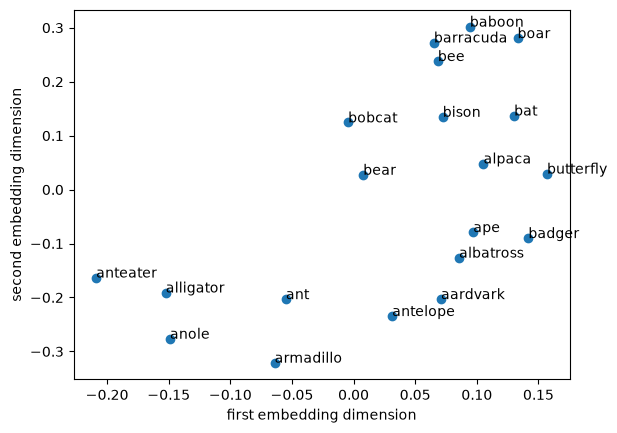

 10%|█         | 1/10 [00:00<00:00,  9.49it/s]

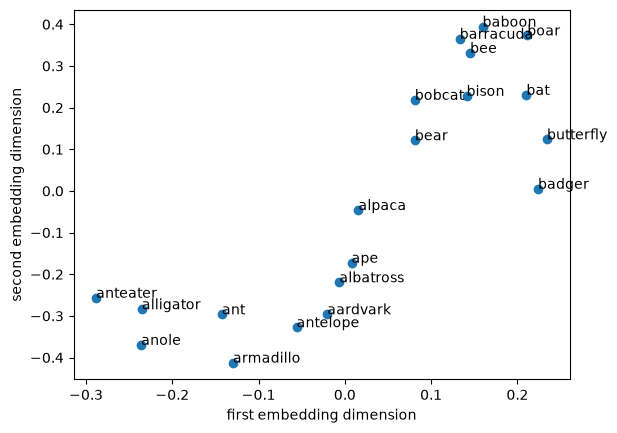

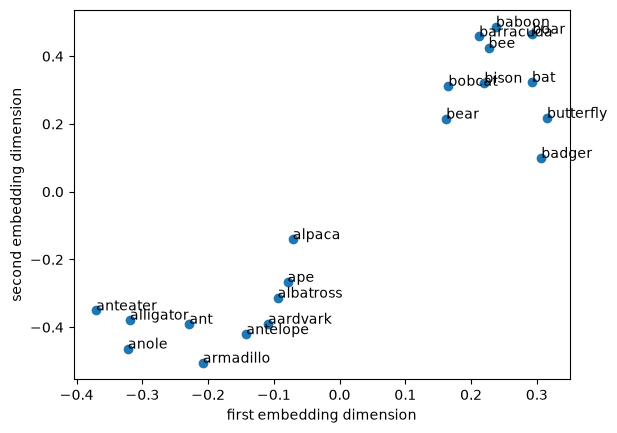

 30%|███       | 3/10 [00:00<00:00, 11.51it/s]

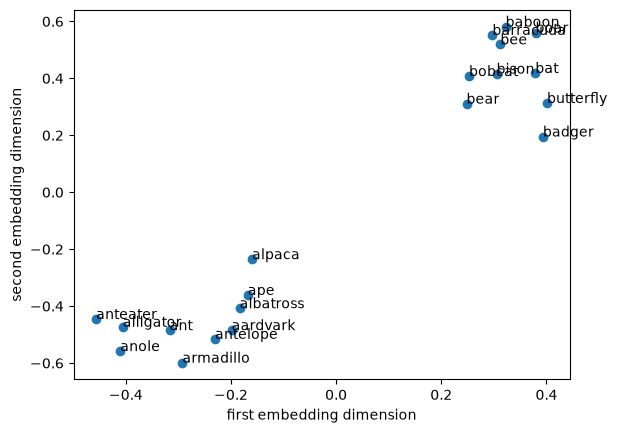

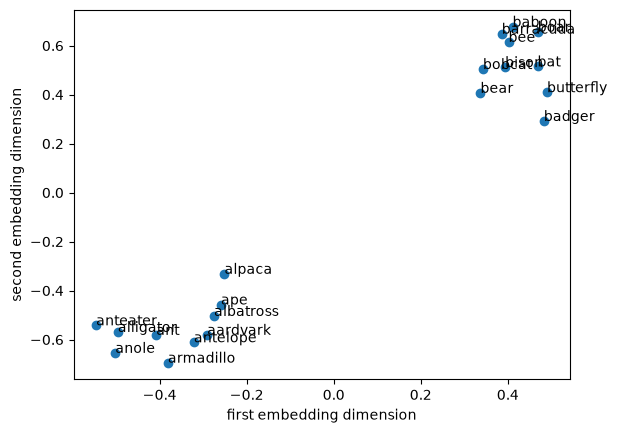

 50%|█████     | 5/10 [00:00<00:00, 11.13it/s]

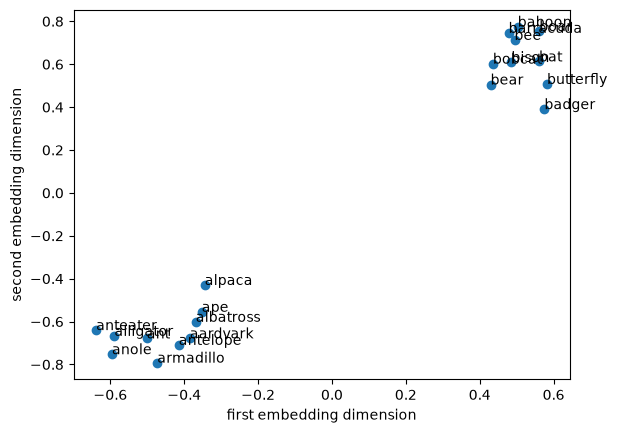

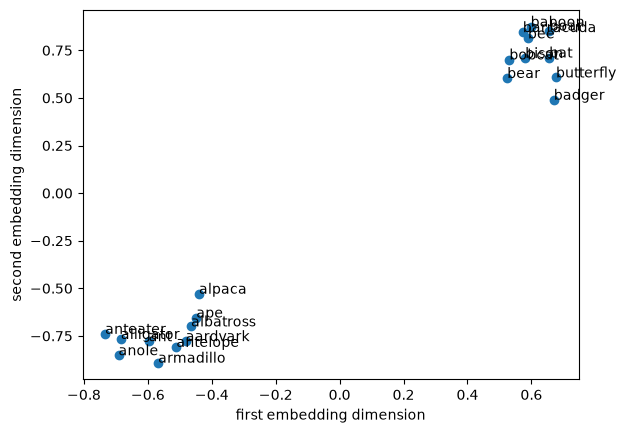

 70%|███████   | 7/10 [00:00<00:00, 11.20it/s]

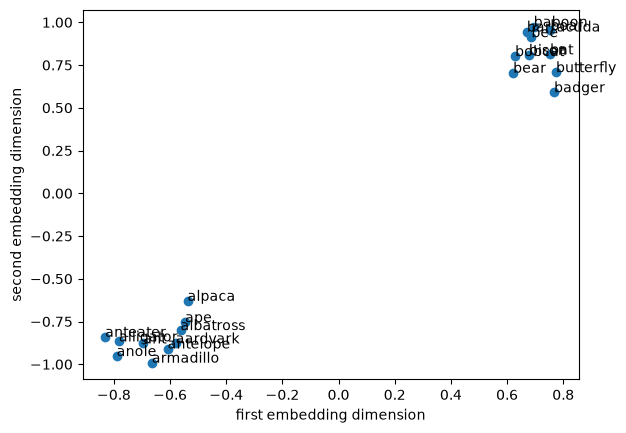

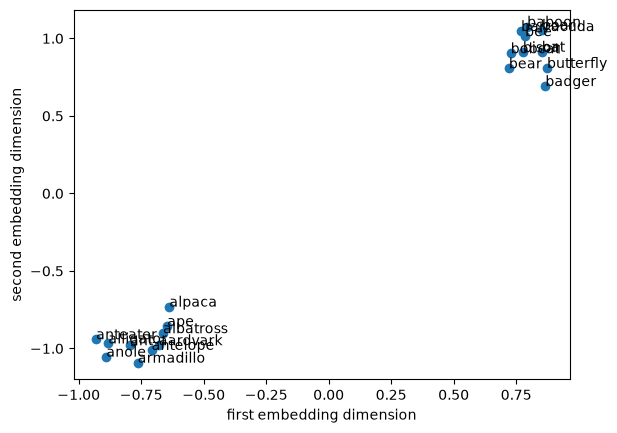

 90%|█████████ | 9/10 [00:00<00:00, 10.53it/s]

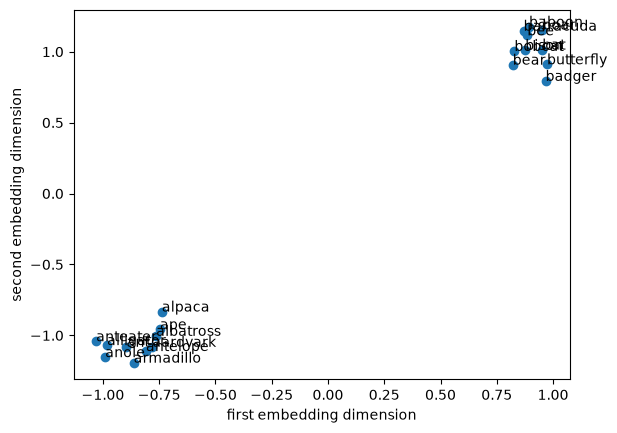

100%|██████████| 10/10 [00:00<00:00, 10.87it/s]


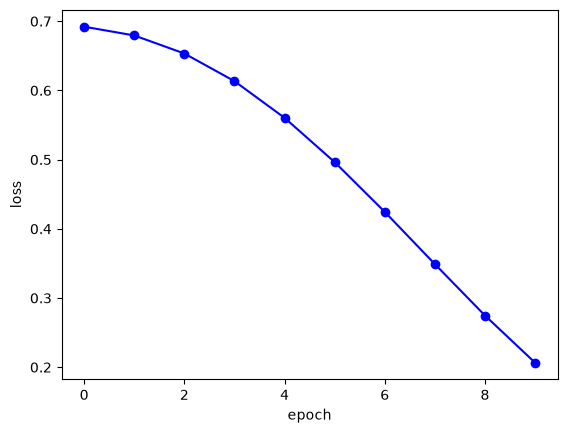

In [90]:
# training the model

def train_word2vec(data, vocab):
    torch.random.manual_seed(42)
    learning_rate = 0.1
    model = Word2Vec(len(vocab), embedding_size = 2, verbose= True)

    # using binary cross entropy
    criterion = nn.BCELoss()

    #fancier version of gradient descent
    optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate)
    model.verbose = False

    loss_val = []
    num_epochs = 10

    #main training loop
    for epoch in tqdm(range(num_epochs), total=num_epochs): # progress bar
    
        optimizer.zero_grad() # resetting all the gradient information
        input1, input2, labels = vectorize_batch2(data, vocab)
        outputs = model(input1, input2)
        
        loss = criterion(outputs, labels)
        loss.backward() # computing all the gradients
        optimizer.step() # update parameters
        loss_val.append(loss.item())
        animal_embeddings = [word2embedding(animal, model, vocab) for animal in animals]
        plot_embeddings(animal_embeddings, animals)


    plt.figure()
    plt.plot(loss_val, 'bo-')
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.show()

    return model


word_2_vec = train_word2vec(data2, vocab)



### RNN

In [92]:
class RNN:
    def __init__(self, n_input, n_hidden, n_output):

        #initialize to small weights
        np.random.seed(42)
        self.W_xh = np.random.randn(n_hidden, n_input) *0.01
        self.W_hh = np.random.randn(n_hidden, n_hidden) *0.01
        self.W_hy = np.random.randn(n_output, n_hidden) *0.01
        self.h = np.random.randn(n_hidden, 1) *0.01

    def step(self, x):
        # update the hidden state
        self.h = np.tanh(np.dot(self.W_hh, self.h) + np.dot(self.w_xh, x))
        # compute output vector
        print(self.h.shape)
        y = np.dot(self.w_hy, self.h)
        return y

    def __str__(self):
        return 'W_xh:\n%s\nW_hh:\n%s\nW_hy:%s\nh:\n%s\n' % (
            str(self.W_xh),
            str(self.W_hh),
            str(self.W_hy),
            str(self.h)
                                                           )

### Full RNN example

In [97]:
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, chars, verbose=True):
        super(RNN, self).__init__()
        self.verbose = verbose
        self.n_hidden = hidden_size

        #W_xh
        self.input_to_hidden = nn.Linear(input_size, hidden_size)

        #W_hh
        self.hidden_to_hidden = nn.Linear(hidden_size, hidden_size)

        #W_hy
        self.hidden_to_output = nn.Linear(hidden_size, output_size)
        self.tanh = nn.Tanh()
        self.softmax = nn.Softmax(dim=1)
        self.chars = chars

    def forward(self, x, h_prev):

        # tanh(w_hh h_t-1 + w_xh x_t)
        h_new = self.tanh(self.hidden_to_hidden(h_prev) + self.input_to_hidden(x))

        output = self.hidden_to_output(h_new)

        if self.verbose:
            display(pd.DataFrame([{
                'input': output2label(x, self.chars),
                'h_new': pp(h_new.detach()),
                'output': pp(output),
                'top output': output2label(output, self.chars)}]).transpose())
        return output, h_new

    def forward_unrolled(self, x_list):
        """
        Given a character list, unroll the network and gather
        predictions for each time step.
        """
        hidden = torch.zeros(1, self.n_hidden)
        outputs = []
        hiddens = []
        for x in x_list[:-1]: # no prediction for final step
            output, hidden = self.forward(x, hidden)
            outputs.append(output)
            hiddens.append(hidden)
        return torch.cat(outputs), hiddens

def pp(arr):
  # pretty print weight array
  return arr.detach().cpu().numpy()[0].round(decimals=2)

def output2label(output, chars):
    """
    return the letter for the most probable prediction
    """
    top_n, top_i = output.topk(1)
    return chars[top_i.item()]


In [98]:
n_chars = 28  # +2 for space and period.
n_hidden = 3

import string

chars = list(string.ascii_lowercase) + [' ', '.']
char2int_d = dict()
int2char_d = dict()
for i, c in enumerate(chars):
    char2int_d[c] = i
    int2char_d[i] = c

sorted(char2int_d.items(), key=lambda x: x[1])

# to create letter "h"
import torch
def char2vec(char, char2int):
    x = torch.zeros((1, len(char2int)))
    x[0][char2int[char]] = 1
    return x

def chars2vec(chars, char2int):
    return torch.cat([char2vec(c, char2int) for c in chars])
print(char2vec('h', char2int_d))
print()
print(chars2vec('hello', char2int_d))

torch.random.manual_seed(42)
rnn = RNN(n_chars, n_hidden, n_chars, chars)
x = char2vec('h', char2int_d)
hidden = torch.zeros(1, n_hidden)
output, hidden = rnn.forward(x, hidden)

tensor([[0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

tensor([[0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


,0
input,h
h_new,"[0.64, -0.12, -0.16]"
output,"[-0.54, 0.3, 0.16, -0.15, 0.03, -0.39, -0.18, ..."
top output,t


In [99]:
chars = ['a', 'b', 'c']
char2int = {'a': 0, 'b': 1, 'c': 2}
int2char = {0: 'a', 1: 'b', 2: 'c'}
data = [
    chars2vec('abcabcabc', char2int),
    chars2vec('bcabcabca', char2int),
    chars2vec('cabcabcab', char2int)
]  * 100

len(data)

300

#### Training the model

In [102]:
from tqdm import tqdm

def train_model(model, data, epochs=20, learning_rate=0.1, batch_size=10):
    """
    Iterate through the data in batches and train the model."""

    torch.random.manual_seed(42)
    np.random.seed(42)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr= learning_rate)

    model.verbose = False
    loss_val = []

    for epoch in range(epochs):
        print('epoch=%d' % epoch)
        np.random.shuffle(data)
        epoch_loss = 0

        with tqdm(total=len(data), desc=f'Epoch {epoch+1}/{epochs}', unit='sample') as pbar:
            for i in range(0, len(data), batch_size):
                batch = data[i:i + batch_size]
                optimizer.zero_grad()
                batch_loss = 0

                for datum in batch:
                    result = model.forward_unrolled(datum)
                    loss = criterion(result[0], datum[1:]. argmax(dim=1).long())
                    batch_loss += loss

                batch_loss /=batch_size
                batch_loss.backward()
                optimizer.step()
                loss_val.append(batch_loss.item())
                epoch_loss += batch_loss
                pbar.update(len(batch))
            pbar.set_postfix({'Batch': (i // batch_size) + 1, 'Loss': batch_loss.item()})

        avg_epoch_loss = epoch_loss / (len(data) / batch_size)
        print(f'Epoch [{epoch+1}/{epochs}], Average Loss: {avg_epoch_loss:.4f}')


    plt.figure()
    plt.plot(loss_val, 'bo-')
    plt.ylabel('loss')
    plt.xlabel('batches')
    plt.show()
    return model


epoch=0


Epoch 1/2: 100%|██████████| 300/300 [00:00<00:00, 1277.73sample/s, Batch=30, Loss=0.000113]


Epoch [1/2], Average Loss: 0.1565
epoch=1


Epoch 2/2: 100%|██████████| 300/300 [00:00<00:00, 1921.17sample/s, Batch=30, Loss=4.43e-5]


Epoch [2/2], Average Loss: 0.0001


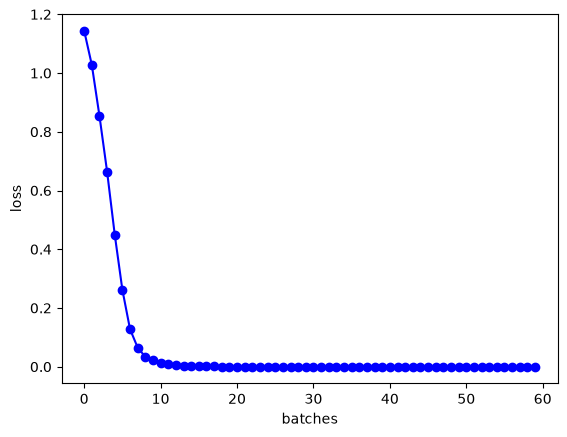

RNN(
  (input_to_hidden): Linear(in_features=3, out_features=3, bias=True)
  (hidden_to_hidden): Linear(in_features=3, out_features=3, bias=True)
  (hidden_to_output): Linear(in_features=3, out_features=3, bias=True)
  (tanh): Tanh()
  (softmax): Softmax(dim=1)
)

In [103]:
rnn = RNN(len(chars), 3, len(chars), chars)
train_model(rnn, data, epochs=2, learning_rate=.2, batch_size=10)